# Phase 2 — Collisions aggregated by ZIP × year
**Contributor:** Yassin · GIU ICS503 · NYC Build and Crash  
**Input:** `data/collisions_step2.csv.gz` — Ahmed's cleaned, crash-level export.  
**Output:** `data/collisions_zip_year.csv` — one observed row per `(zip_code, year)`.

This notebook uses the already verified local live extraction generated on **2026-11-07**:
448,091 crashes, 31 columns, dates **2022-01-01 through 2026-11-03**. It never downloads data or reruns
Ahmed's notebook. Snapshot expectations are evidence checks, separate from the general functions.
If the input changes, stop and independently validate the new handoff before updating that evidence.

## How to run
Open the repository root in **VS Code**, select its existing **`.venv`** kernel, then Restart Kernel
and Run All. The implementation was tested with **Python 3.14.8** and the shared
`pip install -r requirements.txt` environment. `Path.cwd()` must be the repository root.
The input must already exist. Generated CSV and temporary test files stay under ignored `data/`.
The export reuses an identical existing output and refuses to overwrite a different output.


## 1. Why aggregate before the join?
A crash and a building application describe different events. Joining individual records merely
because ZIP and year match would multiply each crash by the number of applications in that cell,
inflating both domains' counts. Each side must first produce a unique ZIP/year summary; Issa can then
join the summaries with one-to-one key validation.

ZIP provides the shared geographic identifier, and calendar year aligns filing and collision dates
at a practical common grain. A filing year is not a construction completion year. This is a study of
**association**, with no causal inference or traffic-exposure denominator. This notebook does not
join housing, complete an absent ZIP/year grid, annualize partial years, or invent geographic values.

Missing ZIPs are excluded **only from this geographic aggregate**. Their original rows and casualty
values remain in Ahmed's gzip for citywide analysis. A modal borough summarizes observed labels;
it is not a recovered location or a replacement in the source records.


In [1]:
from pathlib import Path
from collections import Counter
import hashlib
import os
import subprocess
import tempfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter

PROJECT_ROOT = Path.cwd()
NOTEBOOK_NAME = 'phase2_collisions_aggregation_yassin.ipynb'
INPUT_PATH = Path('data/collisions_step2.csv.gz')
OUTPUT_PATH = Path('data/collisions_zip_year.csv')
VALIDATION_DIR = Path('data/validation/phase2')
assert (PROJECT_ROOT / NOTEBOOK_NAME).is_file(), 'Start the kernel in the repository root'
assert INPUT_PATH.is_file(), 'Generate/obtain Ahmed\'s verified Stage 2 handoff before running'
VALIDATION_DIR.mkdir(parents=True, exist_ok=True)

KEYS = ['zip_code', 'year']
CASUALTY_MAP = {
    'persons_injured': 'number_of_persons_injured',
    'persons_killed': 'number_of_persons_killed',
    'pedestrians_injured': 'number_of_pedestrians_injured',
    'pedestrians_killed': 'number_of_pedestrians_killed',
    'cyclist_injured': 'number_of_cyclist_injured',
    'cyclist_killed': 'number_of_cyclist_killed',
    'motorist_injured': 'number_of_motorist_injured',
    'motorist_killed': 'number_of_motorist_killed',
}
SOURCE_COUNTS = list(CASUALTY_MAP.values())
FLAGS = ['extreme_injury', 'is_partial_year', 'zip_missing']
FACTOR_COLUMNS = [f'contributing_factor_vehicle_{i}' for i in range(1, 6)]
VEHICLE_COLUMNS = ['vehicle_type_code1', 'vehicle_type_code2', 'vehicle_type_code_3',
                   'vehicle_type_code_4', 'vehicle_type_code_5']
EXPECTED_INPUT_COLUMNS = [
    'collision_id', 'crash_date', 'crash_time', 'year', 'month', 'hour', 'is_partial_year',
    'borough', 'zip_code', 'zip_missing', 'latitude', 'longitude',
] + SOURCE_COUNTS + ['extreme_injury'] + FACTOR_COLUMNS + VEHICLE_COLUMNS
COUNT_COLUMNS = ['collision_count'] + list(CASUALTY_MAP) + ['extreme_injury_count']
OUTPUT_COLUMNS = ['zip_code', 'year', 'borough'] + COUNT_COLUMNS + ['top_contributing_factor', 'is_partial_year']
BOROUGHS = {'Bronx', 'Brooklyn', 'Manhattan', 'Queens', 'Staten Island'}
INT64_MAX = np.iinfo(np.int64).max

def file_sha256(path):
    """Hash the complete file without changing it."""
    digest = hashlib.sha256()
    with Path(path).open('rb') as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b''):
            digest.update(chunk)
    return digest.hexdigest()

def require(condition, message):
    """Raise a clear validation failure; never silently repair an incompatible handoff."""
    if not bool(condition):
        raise ValueError(message)

def parse_boolean_text(series, name):
    """Accept only literal CSV True/False; never use truthiness of nonempty strings."""
    require(series.notna().all() and series.isin(['True', 'False']).all(),
            f'{name}: expected nonmissing literal True/False values')
    return series.map({'True': True, 'False': False}).astype(bool)

def read_stage2(path):
    """Load the local handoff with explicit identifiers, Booleans, and strict date parsing."""
    types = {c: 'string' for c in ['zip_code', 'collision_id', 'borough'] + FACTOR_COLUMNS + VEHICLE_COLUMNS + FLAGS}
    frame = pd.read_csv(path, dtype=types, keep_default_na=False, na_values=[''])
    require(frame.columns.tolist() == EXPECTED_INPUT_COLUMNS, 'Unexpected Stage 2 schema/order; report it before proceeding')
    for column in FLAGS:
        frame[column] = parse_boolean_text(frame[column], column)
    frame['crash_date'] = pd.to_datetime(frame['crash_date'], errors='raise')
    return frame

def validate_source_frame(frame):
    """Validate the agreed crash-level contract without altering any input values."""
    require(frame.columns.tolist() == EXPECTED_INPUT_COLUMNS, 'Source schema differs from the Stage 2 contract')
    require(not frame.empty, 'The source handoff is empty')
    ids = frame['collision_id']
    require(ids.notna().all() and ids.map(lambda x: isinstance(x, str) and bool(x.strip())).all(), 'Missing/blank/nontext collision ID')
    require(not ids.duplicated().any(), 'Duplicate collision IDs: investigate rather than dropping them here')
    dates = pd.to_datetime(frame['crash_date'], errors='raise')
    require(dates.notna().all() and dates.ge(pd.Timestamp('2022-01-01')).all(), 'Missing date or crash before 2022')
    require(dates.eq(dates.dt.normalize()).all(), 'Unexpected non-midnight crash_date representation')
    require(pd.api.types.is_integer_dtype(frame['year']) and frame['year'].eq(dates.dt.year).all(), 'Year must be integer and match crash_date')
    require(frame['month'].eq(dates.dt.month).all(), 'Month differs from crash_date')
    require(pd.api.types.is_integer_dtype(frame['hour']) and frame['hour'].between(0, 23).all(), 'Invalid hour')
    zips = frame['zip_code'].dropna()
    require(all(isinstance(x, str) for x in zips) and zips.str.fullmatch(r'[0-9]{5}').all(), 'ZIP must be exactly five text digits')
    require(zips.between('10001', '11697').all(), 'ZIP outside Ahmed\'s validated range; investigate source')
    boroughs = frame['borough'].dropna()
    require(boroughs.isin(BOROUGHS).all(), 'Unexpected borough spelling/case; do not invent a mapping')
    for column in FLAGS:
        require(pd.api.types.is_bool_dtype(frame[column]) and frame[column].notna().all(), f'{column} must contain nonmissing Booleans')
    require(frame['zip_missing'].eq(frame['zip_code'].isna()).all(), 'zip_missing flag disagrees with ZIP nulls')
    latest = dates.max()
    require(latest < pd.Timestamp(year=latest.year, month=12, day=31), 'Latest year reaches Dec 31; review partial-year meaning before use')
    require(frame['is_partial_year'].eq(frame['year'].eq(latest.year)).all(), 'Partial-year flag differs from the latest incomplete year')
    for column in SOURCE_COUNTS:
        values = frame[column]
        require(pd.api.types.is_numeric_dtype(values) and not pd.api.types.is_bool_dtype(values), f'{column} is not numeric casualty data')
        require(values.notna().all() and np.isfinite(values.to_numpy(dtype='float64')).all(), f'{column} contains missing/nonfinite counts')
        require(values.ge(0).all() and values.mod(1).eq(0).all(), f'{column} contains negative/fractional counts')
        require(int(values.max()) <= INT64_MAX, f'{column} exceeds int64 range')
    require(frame['extreme_injury'].eq(frame['number_of_persons_injured'].ge(15)).all(), 'extreme_injury flag differs from >=15 injured')
    for total, parts in [
        ('number_of_persons_injured', ['number_of_pedestrians_injured', 'number_of_cyclist_injured', 'number_of_motorist_injured']),
        ('number_of_persons_killed', ['number_of_pedestrians_killed', 'number_of_cyclist_killed', 'number_of_motorist_killed']),
    ]:
        # Python integer addition avoids overflow even while validating an incompatible source.
        parts_sum = frame[parts].apply(lambda row: sum(int(v) for v in row), axis=1)
        require(frame[total].ge(parts_sum).all(), f'{total} is below its road-user subgroup sum')
    return True


## 2. Load and verify the agreed snapshot
Identifier strings are preserved. CSV Boolean text is parsed explicitly, and malformed flags, dates,
counts, identifiers or schema changes stop execution. No source values are filled or repaired here.
The SHA-256 below identifies the already approved gzip; it is not part of the aggregation algorithm.


In [2]:
input_hash_before = file_sha256(INPUT_PATH)
EXPECTED_SNAPSHOT_SHA256 = 'daed82379e27e13790682b02070842ead4f9a52e41abe4eb67bdba9447d146df'
assert input_hash_before == EXPECTED_SNAPSHOT_SHA256, 'Input changed: independently validate the handoff before updating snapshot evidence'
source = read_stage2(INPUT_PATH)
validate_source_frame(source)
source_dates = source['crash_date']
latest_date = source_dates.max()
latest_year = int(latest_date.year)
print('Input:', INPUT_PATH)
print('Rows / columns:', source.shape)
print('Crash dates:', source_dates.min().date(), 'through', latest_date.date())
print('Unique collision IDs:', source['collision_id'].nunique())
print('Input SHA-256:', input_hash_before)
display(source.dtypes.rename('loaded_dtype').to_frame())


Input: data\collisions_step2.csv.gz
Rows / columns: (448091, 31)
Crash dates: 2022-01-01 through 2026-11-03


Unique collision IDs: 448091
Input SHA-256: daed82379e27e13790682b02070842ead4f9a52e41abe4eb67bdba9447d146df


,loaded_dtype
collision_id,string
crash_date,datetime64[us]
crash_time,str
year,int64
month,int64
hour,int64
is_partial_year,bool
borough,string
zip_code,string
zip_missing,bool


## 3. Missing ZIP exclusions and selection bias
A record without a ZIP cannot be assigned to a ZIP/year cell. Exclude it only from the geographic
summary, preserving the source gzip. Report both record exclusions and all eight excluded casualty
totals: an excluded record is not equivalent to zero collisions or zero casualties.

ZIP absence is uneven: the verified input loses roughly 34% of 2022 crashes and 32% of 2023 crashes,
compared with roughly 20% in 2025. ZIP-level counts therefore have unequal coverage over time.
Changes in geographic counts may partly reflect reporting completeness, not changes in safety.


In [3]:
def summarize_exclusions(frame):
    """Reconcile input, eligible and excluded records/casualties without imputing geography."""
    missing = frame['zip_code'].isna()
    by_year = frame.groupby('year', sort=True).agg(
        input_records=('collision_id', 'size'), excluded_missing_zip=('zip_missing', 'sum'))
    by_year['valid_zip_records'] = by_year['input_records'] - by_year['excluded_missing_zip']
    by_year['excluded_percent'] = 100 * by_year['excluded_missing_zip'] / by_year['input_records']
    by_year = by_year.reset_index()
    casualty_rows = []
    for output, column in CASUALTY_MAP.items():
        all_total = sum(int(x) for x in frame[column])
        excluded = sum(int(x) for x in frame.loc[missing, column])
        eligible_total = sum(int(x) for x in frame.loc[~missing, column])
        assert all_total == eligible_total + excluded
        casualty_rows.append({'metric': output, 'all_records': all_total,
                              'eligible_records': eligible_total, 'excluded_missing_zip': excluded})
    assert int(by_year['input_records'].sum()) == len(frame)
    assert int(by_year['excluded_missing_zip'].sum()) == int(missing.sum())
    assert int(by_year['valid_zip_records'].sum()) + int(missing.sum()) == len(frame)
    return by_year, pd.DataFrame(casualty_rows)

eligible = source.loc[source['zip_code'].notna()].copy()
excluded = source.loc[source['zip_code'].isna()]
year_coverage, casualty_coverage = summarize_exclusions(source)
print(f'Input: {len(source):,}; excluded missing ZIP: {len(excluded):,} ({len(excluded) / len(source):.6%}); eligible: {len(eligible):,}')
display(year_coverage.round({'excluded_percent': 6}))
display(casualty_coverage)


Input: 448,091; excluded missing ZIP: 126,732 (28.282648%); eligible: 321,359


,year,input_records,excluded_missing_zip,valid_zip_records,excluded_percent
0,2022,103888,35144,68744,33.828739
1,2023,96608,30920,65688,32.005631
2,2024,91316,26145,65171,28.631346
3,2025,85559,17091,68468,19.975689
4,2026,70720,17432,53288,24.649321


,metric,all_records,eligible_records,excluded_missing_zip
0,persons_injured,252230,169747,82483
1,persons_killed,1261,721,540
2,pedestrians_injured,44219,35952,8267
3,pedestrians_killed,569,373,196
4,cyclist_injured,24042,19353,4689
5,cyclist_killed,87,61,26
6,motorist_injured,171021,103939,67082
7,motorist_killed,484,205,279


## 4. Metric definitions and category decisions
Every output row represents an **observed** ZIP/year with at least one eligible crash. Count columns
use `int64`. No absent ZIP/year cells are generated or filled with zero.

| Output column | Definition |
|---|---|
| `zip_code` | Source five-digit string; no imputation |
| `year` | Integer crash calendar year |
| `collision_count` | Number of eligible crash records, not number of injured people |
| `persons_injured` | Sum of `number_of_persons_injured` |
| `persons_killed` | Sum of `number_of_persons_killed` |
| `pedestrians_injured` | Sum of `number_of_pedestrians_injured` |
| `pedestrians_killed` | Sum of `number_of_pedestrians_killed` |
| `cyclist_injured` | Sum of `number_of_cyclist_injured` |
| `cyclist_killed` | Sum of `number_of_cyclist_killed` |
| `motorist_injured` | Sum of `number_of_motorist_injured` |
| `motorist_killed` | Sum of `number_of_motorist_killed` |
| `extreme_injury_count` | Sum of verified Boolean `extreme_injury` (persons injured ≥15); these crashes stay in all totals |
| `top_contributing_factor` | Modal informative `contributing_factor_vehicle_1` within this ZIP/year |
| `borough` | Modal nonmissing borough **per ZIP across all eligible years**, then mapped onto each ZIP/year |
| `is_partial_year` | Verified source flag, uniform within each year/group; latest observed year is incomplete |

For factors, strip/collapse whitespace and exclude missing/empty values, `Unspecified`, and
`Does Not Apply`, with case-insensitive exclusions. Retain other category spellings. If no informative
value remains, export a genuine missing value (empty CSV field), never a fictional label.

For either category mode, break equal-frequency ties by **case-insensitive alphabetical order**, then
exact spelling. This is deterministic and independent of input order. Borough values remain Title Case.
All observed ZIP/borough conflicts and vote counts are printed below; choosing a representative label
does not erase minority labels from the source or establish an authoritative geographic boundary.


In [4]:
def informative_factors(values):
    """Normalize whitespace and exclude only missing/empty and named non-informative factors."""
    text = values.astype('string').str.strip().str.replace(r'\s+', ' ', regex=True)
    excluded = text.isna() | text.eq('') | text.str.casefold().isin({'unspecified', 'does not apply'})
    return text.mask(excluded, pd.NA)

def deterministic_mode(values):
    """Frequency first; ties use casefolded alphabetical order then exact spelling."""
    frequencies = values.dropna().astype('string').value_counts(sort=False)
    if frequencies.empty:
        return pd.NA
    candidates = pd.DataFrame({'label': frequencies.index.tolist(), 'votes': frequencies.to_numpy()})
    candidates['casefold'] = candidates['label'].str.casefold()
    return candidates.sort_values(['votes', 'casefold', 'label'], ascending=[False, True, True], kind='stable').iloc[0]['label']

def borough_decisions(eligible_frame):
    """Select one observed modal borough per ZIP across years and expose every conflicting label."""
    modes = eligible_frame.groupby('zip_code', sort=True)['borough'].agg(deterministic_mode).astype('string')
    votes = eligible_frame.dropna(subset=['borough']).groupby(['zip_code', 'borough'], sort=True).size().rename('records').reset_index()
    distinct = votes.groupby('zip_code')['borough'].nunique()
    conflicts = votes.loc[votes['zip_code'].isin(distinct[distinct > 1].index)].copy()
    conflicts['known_borough_records_for_zip'] = conflicts.groupby('zip_code')['records'].transform('sum')
    conflicts['share_percent'] = 100 * conflicts['records'] / conflicts['known_borough_records_for_zip']
    conflicts['selected_borough'] = conflicts['zip_code'].map(modes)
    conflicts['selected'] = conflicts['borough'].eq(conflicts['selected_borough'])
    return modes, conflicts.reset_index(drop=True)

def empty_aggregate():
    """A source with no eligible ZIPs produces zero rows, never invented geographic cells."""
    return pd.DataFrame({c: pd.Series(dtype=('string' if c in ['zip_code', 'borough', 'top_contributing_factor']
                                            else 'bool' if c == 'is_partial_year' else 'int64')) for c in OUTPUT_COLUMNS})

def aggregate_zip_year(frame):
    """Return observed ZIP/year summaries; leave source records untouched."""
    validate_source_frame(frame)
    work = frame.loc[frame['zip_code'].notna()].copy()
    if work.empty:
        return empty_aggregate()
    # Counts are nonnegative. A checked Python-integer grand total bounds every group sum.
    for column in SOURCE_COUNTS:
        require(sum(int(x) for x in work[column]) <= INT64_MAX, f'{column}: aggregate would overflow int64')
        work[column] = work[column].astype('int64')
    work['_informative_factor'] = informative_factors(work['contributing_factor_vehicle_1'])
    specification = {'collision_count': ('collision_id', 'size')}
    specification.update({output: (column, 'sum') for output, column in CASUALTY_MAP.items()})
    specification.update({'extreme_injury_count': ('extreme_injury', 'sum'),
                          'top_contributing_factor': ('_informative_factor', deterministic_mode),
                          'is_partial_year': ('is_partial_year', 'first')})
    result = work.groupby(KEYS, sort=True, observed=True).agg(**specification).reset_index()
    modes, _ = borough_decisions(work)
    result['borough'] = result['zip_code'].map(modes).astype('string')
    for column in ['zip_code', 'top_contributing_factor']:
        result[column] = result[column].astype('string')
    result['year'] = result['year'].astype('int64')
    result[COUNT_COLUMNS] = result[COUNT_COLUMNS].astype('int64')
    result['is_partial_year'] = result['is_partial_year'].astype(bool)
    return result[OUTPUT_COLUMNS].sort_values(KEYS, kind='stable').reset_index(drop=True)

zip_borough_modes, borough_conflicts = borough_decisions(eligible)
print('ZIPs with conflicting nonmissing borough labels:', borough_conflicts['zip_code'].nunique())
display(borough_conflicts.round({'share_percent': 6}))
aggregate = aggregate_zip_year(source)
print('Aggregated rows / columns:', aggregate.shape)
display(aggregate.head(10))


ZIPs with conflicting nonmissing borough labels: 5


,zip_code,borough,records,known_borough_records_for_zip,share_percent,selected_borough,selected
0,11208,Brooklyn,4933,4957,99.515836,Brooklyn,True
1,11208,Queens,24,4957,0.484164,Brooklyn,False
2,11237,Brooklyn,2324,2395,97.035491,Brooklyn,True
3,11237,Queens,71,2395,2.964509,Brooklyn,False
4,11385,Brooklyn,14,4145,0.337756,Queens,False
5,11385,Queens,4131,4145,99.662244,Queens,True
6,11414,Brooklyn,1,896,0.111607,Queens,False
7,11414,Queens,895,896,99.888393,Queens,True
8,11421,Brooklyn,5,1179,0.424088,Queens,False
9,11421,Queens,1174,1179,99.575912,Queens,True


Aggregated rows / columns: (1040, 15)


,zip_code,year,borough,collision_count,persons_injured,persons_killed,pedestrians_injured,pedestrians_killed,cyclist_injured,cyclist_killed,motorist_injured,motorist_killed,extreme_injury_count,top_contributing_factor,is_partial_year
0,10001,2022,Manhattan,517,198,1,77,1,46,0,65,0,0,Driver Inattention/Distraction,False
1,10001,2023,Manhattan,458,185,2,50,1,42,0,82,1,0,Driver Inattention/Distraction,False
2,10001,2024,Manhattan,495,233,0,85,0,62,0,76,0,0,Driver Inattention/Distraction,False
3,10001,2025,Manhattan,551,248,1,89,1,56,0,82,0,0,Driver Inattention/Distraction,False
4,10001,2026,Manhattan,501,230,1,69,0,62,0,79,0,0,Driver Inattention/Distraction,True
5,10002,2022,Manhattan,743,353,1,96,1,85,0,141,0,0,Driver Inattention/Distraction,False
6,10002,2023,Manhattan,750,403,2,95,2,87,0,198,0,0,Driver Inattention/Distraction,False
7,10002,2024,Manhattan,664,338,5,97,5,82,0,146,0,0,Driver Inattention/Distraction,False
8,10002,2025,Manhattan,618,283,1,79,1,63,0,109,0,0,Driver Inattention/Distraction,False
9,10002,2026,Manhattan,586,296,0,83,0,64,0,116,0,0,Driver Inattention/Distraction,True


## 5. Validate keys, sums, categories and partial-year flags
The checks reconcile every output count to eligible input records. They also recompute category
winners independently with `Counter`, check the all-years borough decision, and ensure no extra
ZIP/year combinations were introduced. Snapshot-specific expectations are checked separately.


In [5]:
def same_label(left, right):
    """Missing is equal only to missing for category verification."""
    return bool(pd.isna(left) and pd.isna(right)) if pd.isna(left) or pd.isna(right) else left == right

def counter_winner(values):
    """Independent mode reference for validation, without the production mode function."""
    counts = Counter(x for x in values if not pd.isna(x))
    if not counts:
        return pd.NA
    maximum = max(counts.values())
    return min((x for x, count in counts.items() if count == maximum), key=lambda x: (x.casefold(), x))

def validate_aggregate(result, frame):
    """Verify the complete aggregate against its source, including all category decisions."""
    require(result.columns.tolist() == OUTPUT_COLUMNS, 'Unexpected aggregate schema/order')
    valid = frame.loc[frame['zip_code'].notna()]
    require(not result.duplicated(KEYS).any(), 'Duplicate output keys: unsafe many-to-many handoff')
    require(result['zip_code'].notna().all() and all(isinstance(x, str) for x in result['zip_code'])
            and result['zip_code'].str.fullmatch(r'[0-9]{5}').all(), 'Output ZIPs must be five-digit strings')
    require(pd.api.types.is_integer_dtype(result['year']) and result['year'].ge(2022).all(), 'Output years invalid')
    expected_keys = set(valid[KEYS].itertuples(index=False, name=None))
    require(set(result[KEYS].itertuples(index=False, name=None)) == expected_keys, 'Missing or invented output keys')
    for column in COUNT_COLUMNS:
        require(str(result[column].dtype) == 'int64' and result[column].notna().all()
                and result[column].ge(0).all(), f'{column}: counts must be nonmissing nonnegative int64')
    require(result['collision_count'].gt(0).all(), 'No zero-filled absent groups are allowed')
    require(sum(int(x) for x in result['collision_count']) == len(valid), 'Collision counts do not reconcile')
    for output, column in CASUALTY_MAP.items():
        require(sum(int(x) for x in result[output]) == sum(int(x) for x in valid[column]), f'{output} total differs from eligible source')
    require(int(result['extreme_injury_count'].sum()) == int(valid['extreme_injury'].sum()), 'Extreme-injury totals differ')
    require(result['extreme_injury_count'].le(result['collision_count']).all(), 'Extreme crashes exceed all crashes')
    require(pd.api.types.is_bool_dtype(result['is_partial_year']) and result['is_partial_year'].notna().all(), 'Partial flag must be Boolean')
    reference_borough = {z: counter_winner(g['borough']) for z, g in valid.groupby('zip_code', sort=True)}
    lookup = result.set_index(KEYS)
    for key, group in valid.groupby(KEYS, sort=True):
        row = lookup.loc[key]
        require(int(row['collision_count']) == len(group), f'{key}: collision count differs')
        for output, column in CASUALTY_MAP.items():
            require(int(row[output]) == sum(int(x) for x in group[column]), f'{key}: {output} differs')
        require(int(row['extreme_injury_count']) == int(group['extreme_injury'].sum()), f'{key}: extreme count differs')
        require(group['is_partial_year'].nunique() == 1 and bool(row['is_partial_year']) == bool(group['is_partial_year'].iloc[0]), f'{key}: partial flag differs')
        require(same_label(row['borough'], reference_borough[key[0]]), f'{key}: borough differs from all-years ZIP mode')
        # Scalar normalization is independent of the vectorized production factor normalizer.
        normalized = []
        for value in group['contributing_factor_vehicle_1']:
            if pd.isna(value):
                continue
            label = ' '.join(str(value).split())
            if label and label.casefold() not in {'unspecified', 'does not apply'}:
                normalized.append(label)
        require(same_label(row['top_contributing_factor'], counter_winner(normalized)), f'{key}: factor winner/tie rule differs')
    return True

validate_aggregate(aggregate, source)
assert source.shape == (448091, 31)
assert source_dates.min() == pd.Timestamp('2022-01-01') and latest_date == pd.Timestamp('2026-11-03')
assert len(eligible) == 321359 and len(excluded) == 126732
assert np.isclose(100 * len(excluded) / len(source), 28.282648, rtol=0, atol=0.0000005)
assert len(aggregate) == 1040 and aggregate['zip_code'].nunique() == 228
assert int(aggregate['collision_count'].sum()) == 321359
assert int(aggregate['persons_injured'].sum()) == 169747
assert int(aggregate['persons_killed'].sum()) == 721
assert int(aggregate['extreme_injury_count'].sum()) == 17
assert set(borough_conflicts['zip_code']) == {'11208', '11237', '11385', '11414', '11421'}
assert aggregate['is_partial_year'].eq(aggregate['year'].eq(latest_year)).all()
print('PASS: unique keys, exact eligible sums, all group/category decisions, flags and verified snapshot evidence.')
print('Rows:', len(aggregate), '| distinct ZIPs:', aggregate['zip_code'].nunique())
display(aggregate[COUNT_COLUMNS].sum().rename('eligible_source_and_aggregate_total').to_frame())
print('Groups without an informative factor:', int(aggregate['top_contributing_factor'].isna().sum()))


PASS: unique keys, exact eligible sums, all group/category decisions, flags and verified snapshot evidence.
Rows: 1040 | distinct ZIPs: 228


,eligible_source_and_aggregate_total
collision_count,321359
persons_injured,169747
persons_killed,721
pedestrians_injured,35952
pedestrians_killed,373
cyclist_injured,19353
cyclist_killed,61
motorist_injured,103939
motorist_killed,205
extreme_injury_count,17


Groups without an informative factor: 35


## 6. Visual validation of geographic coverage
Compare the same source population before and after ZIP eligibility. The gap is excluded records,
not a reduction in real collisions. The latest year is marked partial through the actual last date;
these are counts, not exposure-adjusted collision rates or comparable full-year totals.


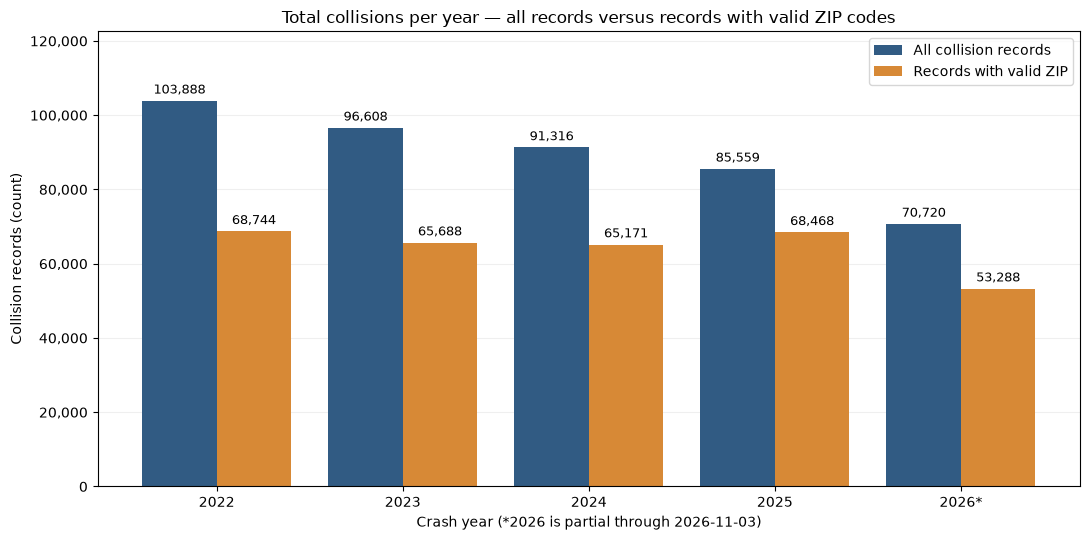

Plot source counts:


,year,input_records,valid_zip_records
0,2022,103888,68744
1,2023,96608,65688
2,2024,91316,65171
3,2025,85559,68468
4,2026,70720,53288


In [6]:
x = np.arange(len(year_coverage))
fig, ax = plt.subplots(figsize=(11, 5.5))
all_bars = ax.bar(x - 0.2, year_coverage['input_records'], width=0.4, label='All collision records', color='#315b83')
valid_bars = ax.bar(x + 0.2, year_coverage['valid_zip_records'], width=0.4, label='Records with valid ZIP', color='#d78936')
ax.bar_label(all_bars, labels=[f'{int(v):,}' for v in year_coverage['input_records']], padding=3, fontsize=9)
ax.bar_label(valid_bars, labels=[f'{int(v):,}' for v in year_coverage['valid_zip_records']], padding=3, fontsize=9)
labels = [f'{int(y)}*' if int(y) == latest_year else str(int(y)) for y in year_coverage['year']]
ax.set_xticks(x, labels)
ax.set_title('Total collisions per year — all records versus records with valid ZIP codes')
ax.set_xlabel(f'Crash year (*{latest_year} is partial through {latest_date.date()})')
ax.set_ylabel('Collision records (count)')
ax.yaxis.set_major_formatter(StrMethodFormatter('{x:,.0f}'))
ax.set_ylim(0, year_coverage['input_records'].max() * 1.18)
ax.legend(loc='upper right')
ax.grid(axis='y', alpha=0.2)
ax.set_axisbelow(True)
fig.tight_layout()
plt.show()
print('Plot source counts:')
display(year_coverage[['year', 'input_records', 'valid_zip_records']])


## 7. Focused offline regression tests
Small synthetic fixtures are used **only for tests**, never mixed with the real input or output.
Tests cover explicit sums, ZIP exclusion, cross-year borough selection, case-insensitive factor
exclusions, both tie rules, input-order invariance, empty eligibility, int64 overflow protection,
rejected malformed source values, and real CSV writing/reloading/conflict behavior.
All temporary test files live in an ignored directory and are removed by `TemporaryDirectory`.


In [7]:
def read_aggregate(path):
    """Reload CSV identifiers/categories without treating legitimate text tokens as null."""
    types = {c: 'string' for c in ['zip_code', 'borough', 'top_contributing_factor', 'is_partial_year']}
    types.update({c: 'int64' for c in ['year'] + COUNT_COLUMNS})
    frame = pd.read_csv(path, dtype=types, keep_default_na=False, na_values=[''])
    require(frame.columns.tolist() == OUTPUT_COLUMNS, 'Export schema/order differs')
    frame['is_partial_year'] = parse_boolean_text(frame['is_partial_year'], 'is_partial_year')
    for column in ['year'] + COUNT_COLUMNS:
        require(pd.api.types.is_integer_dtype(frame[column]) and frame[column].notna().all(), f'Export {column} is not nonmissing integer')
        frame[column] = frame[column].astype('int64')
    return frame

def export_verified(frame, destination):
    """Verify a temporary CSV before promotion; preserve a different existing destination."""
    destination = Path(destination)
    destination.parent.mkdir(parents=True, exist_ok=True)
    if destination.exists():
        try:
            existing = read_aggregate(destination)
            pd.testing.assert_frame_equal(existing, frame, check_exact=True)
        except Exception as exc:
            raise FileExistsError(f'Preserving different/unreadable existing output: {destination}') from exc
        print('Identical existing output reused:', destination)
        return existing
    temporary = None
    try:
        with tempfile.NamedTemporaryFile(mode='w', encoding='utf-8', newline='', dir=destination.parent,
                                         prefix=f'.{destination.stem}_', suffix='.tmp', delete=False) as handle:
            temporary = Path(handle.name)
            frame.to_csv(handle, index=False)
        reloaded = read_aggregate(temporary)
        pd.testing.assert_frame_equal(reloaded, frame, check_exact=True)
        if destination.exists():
            raise FileExistsError(f'Destination appeared during export; preserving it: {destination}')
        temporary.replace(destination)
        temporary = None
        return reloaded
    finally:
        if temporary is not None:
            temporary.unlink(missing_ok=True)  # only this function's own temporary file

def make_test_source(specifications):
    """Construct clearly synthetic Stage 2 fixtures, independent of real records."""
    latest = max(s['year'] for s in specifications)
    rows = []
    for i, specification in enumerate(specifications):
        row = {c: pd.NA for c in EXPECTED_INPUT_COLUMNS}
        row.update({c: 0 for c in SOURCE_COUNTS})
        y = specification['year']
        row.update({'collision_id': f'synthetic-{i}', 'crash_date': pd.Timestamp(year=y, month=6, day=15),
                    'crash_time': '12:00', 'year': y, 'month': 6, 'hour': 12,
                    'latitude': np.nan, 'longitude': np.nan, 'is_partial_year': y == latest,
                    'zip_code': specification.get('zip_code'), 'borough': specification.get('borough'),
                    'contributing_factor_vehicle_1': specification.get('factor'),
                    'number_of_persons_injured': specification.get('injured', 0),
                    'number_of_motorist_injured': specification.get('injured', 0)})
        row['zip_missing'] = bool(pd.isna(row['zip_code']))
        row['extreme_injury'] = row['number_of_persons_injured'] >= 15
        rows.append(row)
    frame = pd.DataFrame(rows, columns=EXPECTED_INPUT_COLUMNS)
    for column in ['collision_id', 'zip_code', 'borough'] + FACTOR_COLUMNS + VEHICLE_COLUMNS:
        frame[column] = frame[column].astype('string')
    frame[SOURCE_COUNTS + ['year', 'month', 'hour']] = frame[SOURCE_COUNTS + ['year', 'month', 'hour']].astype('int64')
    frame[FLAGS] = frame[FLAGS].astype(bool)
    return frame

def expect_rejection(function, exception=ValueError):
    try:
        function()
    except exception:
        return
    raise AssertionError(f'Expected {exception.__name__} was not raised')

def run_focused_tests():
    passed = []
    fixture = make_test_source([
        {'zip_code': '10001', 'year': 2022, 'borough': 'Queens', 'factor': 'Zebra', 'injured': 1},
        {'zip_code': '10001', 'year': 2022, 'borough': 'Queens', 'factor': 'Alpha', 'injured': 20},
        {'zip_code': '10001', 'year': 2023, 'borough': 'Manhattan', 'factor': 'Following Too Closely', 'injured': 2},
        {'zip_code': '10002', 'year': 2023, 'borough': 'Bronx', 'factor': ' UnSpEcIfIeD '},
        {'zip_code': '10002', 'year': 2023, 'borough': 'Bronx', 'factor': 'does NOT apply'},
        {'zip_code': None, 'year': 2022, 'borough': None, 'factor': None, 'injured': 3},
    ])
    before = fixture.copy(deep=True)
    result = aggregate_zip_year(fixture)
    validate_aggregate(result, fixture)
    assert len(result) == 3 and result['collision_count'].sum() == 5
    assert result['persons_injured'].sum() == 23 and result['extreme_injury_count'].sum() == 1
    row = result.set_index(KEYS).loc[('10001', 2022)]
    assert row['collision_count'] == 2 and row['persons_injured'] == 21 and row['top_contributing_factor'] == 'Alpha'
    pd.testing.assert_frame_equal(before, fixture)
    passed.append('normal metrics, exact sums and source-frame preservation')
    years, totals = summarize_exclusions(fixture)
    assert years['excluded_missing_zip'].sum() == 1
    assert totals.set_index('metric').loc['persons_injured', 'excluded_missing_zip'] == 3
    assert len(result) == fixture.loc[fixture['zip_code'].notna(), KEYS].drop_duplicates().shape[0]
    passed.append('missing ZIP exclusion and casualty/key reconciliation')
    assert result.loc[result['zip_code'].eq('10001'), 'borough'].eq('Queens').all()
    modes, conflicts = borough_decisions(fixture.loc[fixture['zip_code'].notna()])
    assert modes['10001'] == 'Queens' and set(conflicts['records']) == {1, 2}
    assert deterministic_mode(pd.Series(['Queens', 'Bronx'], dtype='string')) == 'Bronx'
    passed.append('all-years ZIP borough mode, conflict counts and borough tie')
    assert pd.isna(result.set_index(KEYS).loc[('10002', 2023), 'top_contributing_factor'])
    assert informative_factors(pd.Series([None, '', '   ', 'Unspecified', ' DOES   NOT APPLY ', 'NA'], dtype='string')).isna().tolist() == [True, True, True, True, True, False]
    assert deterministic_mode(pd.Series(['zebra', 'Alpha'])) == 'Alpha'
    assert deterministic_mode(pd.Series(['alpha', 'Alpha'])) == 'Alpha'
    passed.append('factor exclusions, genuine missing mode and deterministic ties')
    for seed in [7, 19]:
        pd.testing.assert_frame_equal(result, aggregate_zip_year(fixture.sample(frac=1, random_state=seed)))
    passed.append('input-order invariance')
    all_missing = make_test_source([{'zip_code': None, 'year': 2023, 'borough': None, 'injured': 3}])
    empty = aggregate_zip_year(all_missing)
    assert empty.empty and empty.columns.tolist() == OUTPUT_COLUMNS
    validate_aggregate(empty, all_missing)
    unknown_borough = make_test_source([{'zip_code': '10001', 'year': 2023, 'borough': None, 'factor': 'NA'}])
    assert pd.isna(aggregate_zip_year(unknown_borough).iloc[0]['borough'])
    passed.append('all-missing ZIPs create no cells; unknown borough is not fabricated')
    malformed = []
    x = fixture.copy(); x.loc[0, 'zip_code'] = '10001.0'; malformed.append(x)
    x = fixture.copy(); x.loc[0, 'collision_id'] = pd.NA; malformed.append(x)
    x = fixture.copy(); x.loc[1, 'collision_id'] = x.loc[0, 'collision_id']; malformed.append(x)
    x = fixture.copy(); x.loc[0, 'crash_date'] = pd.NaT; malformed.append(x)
    x = fixture.copy(); x.loc[0, 'year'] = 2024; malformed.append(x)
    x = fixture.copy(); x.loc[0, 'number_of_persons_injured'] = -1; malformed.append(x)
    x = fixture.copy(); x['number_of_persons_injured'] = x['number_of_persons_injured'].astype(float); x.loc[0, 'number_of_persons_injured'] = 1.5; malformed.append(x)
    x = fixture.copy(); x['number_of_persons_injured'] = x['number_of_persons_injured'].astype(float); x.loc[0, 'number_of_persons_injured'] = np.nan; malformed.append(x)
    x = fixture.copy(); x.loc[0, 'zip_missing'] = True; malformed.append(x)
    x = fixture.copy(); x.loc[0, 'is_partial_year'] = True; malformed.append(x)
    x = fixture.copy(); x.loc[0, 'extreme_injury'] = True; malformed.append(x)
    malformed.append(fixture.drop(columns='year'))
    for x in malformed:
        expect_rejection(lambda x=x: aggregate_zip_year(x))
    expect_rejection(lambda: parse_boolean_text(pd.Series(['False', 'not-a-boolean'], dtype='string'), 'test'))
    passed.append('12 malformed source cases plus invalid Boolean text rejected')
    overflow = fixture.iloc[:2].copy()
    overflow['is_partial_year'] = True
    overflow['number_of_persons_injured'] = np.int64(INT64_MAX)
    overflow['number_of_motorist_injured'] = np.int64(INT64_MAX)
    overflow['extreme_injury'] = True
    expect_rejection(lambda: aggregate_zip_year(overflow))
    passed.append('aggregate int64 overflow rejected before summation')
    with tempfile.TemporaryDirectory(prefix='zip-year-tests-', dir=VALIDATION_DIR) as temporary:
        path = Path(temporary) / 'roundtrip.csv'
        back = export_verified(result, path)
        pd.testing.assert_frame_equal(back, result)
        pd.testing.assert_frame_equal(export_verified(empty, Path(temporary) / 'empty.csv'), empty)
        before_bytes = path.read_bytes()
        pd.testing.assert_frame_equal(export_verified(result, path), result)
        assert path.read_bytes() == before_bytes
        different = result.copy(); different.loc[0, 'collision_count'] += 1
        expect_rejection(lambda: export_verified(different, path), FileExistsError)
        assert path.read_bytes() == before_bytes
        label_case = result.copy(); label_case.loc[0, 'zip_code'] = '00123'; label_case.loc[0, 'top_contributing_factor'] = 'NA'
        label_path = Path(temporary) / 'literal_tokens.csv'
        label_back = export_verified(label_case, label_path)
        assert label_back.loc[0, 'zip_code'] == '00123' and label_back.loc[0, 'top_contributing_factor'] == 'NA'
        bad = Path(temporary) / 'bad.csv'; bad.write_text('unreadable schema\n1\n', encoding='utf-8')
        bad_bytes = bad.read_bytes()
        expect_rejection(lambda: export_verified(result, bad), FileExistsError)
        assert bad.read_bytes() == bad_bytes
    passed.append('real CSV round-trip, identical reuse, conflicts, leading zeros and literal NA preservation')
    return passed

focused_test_results = run_focused_tests()
for i, result in enumerate(focused_test_results, 1):
    print(f'PASS {i}: {result}')
print('Focused regression groups passed:', len(focused_test_results))


Identical existing output reused: D:\NYC-Build-And-Crash-Phase2-Yassin\data\validation\phase2\zip-year-tests-x831mcf7\roundtrip.csv
PASS 1: normal metrics, exact sums and source-frame preservation
PASS 2: missing ZIP exclusion and casualty/key reconciliation
PASS 3: all-years ZIP borough mode, conflict counts and borough tie
PASS 4: factor exclusions, genuine missing mode and deterministic ties
PASS 5: input-order invariance
PASS 6: all-missing ZIPs create no cells; unknown borough is not fabricated
PASS 7: 12 malformed source cases plus invalid Boolean text rejected
PASS 8: aggregate int64 overflow rejected before summation
PASS 9: real CSV round-trip, identical reuse, conflicts, leading zeros and literal NA preservation
Focused regression groups passed: 9


## 8. Export and reload the integration handoff
Verify a temporary CSV before promoting it to `data/collisions_zip_year.csv`. An identical existing
export is reused; a different/unreadable output is preserved and reported as a conflict. Reload ZIPs
as strings and flags as explicit Boolean values. Re-run the full aggregate/source comparison after
export. The original gzip's hash must remain unchanged.


In [8]:
reloaded = export_verified(aggregate, OUTPUT_PATH)
validate_aggregate(reloaded, source)
pd.testing.assert_frame_equal(aggregate, reloaded, check_exact=True)
assert file_sha256(INPUT_PATH) == input_hash_before, 'The Stage 2 source file changed'
ignore = subprocess.run(['git', 'check-ignore', '--quiet', str(OUTPUT_PATH)], capture_output=True, text=True)
assert ignore.returncode == 0, 'Generated CSV must be ignored by Git'
tracked_output = subprocess.run(['git', 'ls-files', '--', str(OUTPUT_PATH)], capture_output=True, text=True, check=True)
assert not tracked_output.stdout.strip(), 'Generated output must not be tracked'
print('PASS: full CSV round-trip, all aggregate checks, source hash unchanged, output ignored/untracked.')
print('Output:', OUTPUT_PATH, '| rows:', len(reloaded), '| columns:', len(reloaded.columns), '| bytes:', OUTPUT_PATH.stat().st_size)
print('Output SHA-256:', file_sha256(OUTPUT_PATH))
print('Execution completed using only the existing local source. No fresh-clone verification is claimed.')


PASS: full CSV round-trip, all aggregate checks, source hash unchanged, output ignored/untracked.
Output: data\collisions_zip_year.csv | rows: 1040 | columns: 15 | bytes: 84689
Output SHA-256: 43fb914a70fbe39a07322599ca72eac135b8ffe53a5ec9d7672bdc76642cc3f1
Execution completed using only the existing local source. No fresh-clone verification is claimed.


## 9. Limitations and handoff to Issa
- **Selection bias:** missing ZIPs exclude 126,732 crashes (28.282648%) from this snapshot's
  geographic analysis; exclusions vary by year and are higher in 2022/2023. Their casualties are
  reported above, not treated as zero. The raw and cleaned crash-level datasets remain available.
- **Partial 2026:** this input ends **2026-11-03**. Do not compare its totals as a complete year,
  assume a full November, annualize mechanically, or reuse the historical October 31 cutoff.
- **No exposure denominator:** counts are reported incidents/casualties, not collision rates or
  individual danger; traffic volumes, population and reporting differences can influence patterns.
- **Borough ambiguity:** five ZIPs have minority borough labels. The documented all-years modal
  label is a summary of observed data, not an authoritative ZIP boundary assignment.
- **Extreme events:** 17 eligible crashes with ≥15 injured remain included and are separately
  counted for later sensitivity analysis. `extreme_injury_count` does not count injured people.
- **Correlation only:** shared geography/year does not demonstrate that construction causes crashes.
- **Observation windows:** align housing filing coverage and crash coverage explicitly before the
  join. Agree any common cutoff with the team, then regenerate affected aggregates consistently;
  a ZIP/year summary cannot retroactively enforce a within-year cutoff on its own.

### Reproduce and load
1. From the repository root, use VS Code and the project `.venv` installed from `requirements.txt`.
2. Obtain the verified `data/collisions_step2.csv.gz` identified by the printed input SHA-256. If it is
   absent, coordinate with Ahmed/Yassin: this notebook stops and does not make API calls. Running
   Ahmed's current live loader may produce a different snapshot requiring independent validation.
3. Restart Kernel and Run All in this notebook. Focused tests, snapshot checks and export verification
   must all pass. Generated files remain ignored; do not commit source/derived datasets.
4. For the join, read `pd.read_csv('data/collisions_zip_year.csv', dtype={'zip_code': 'string',
   'borough': 'string', 'top_contributing_factor': 'string'}, keep_default_na=False, na_values=[''])`;
   verify Boolean `is_partial_year`, integer counts and unique keys. The notebook's `read_aggregate`
   provides an explicit Boolean parser if needed.
5. Join with housing only after both inputs have unique `(zip_code, year)` keys, using
   `validate='one_to_one'`. Issa owns the housing aggregation/join. Unmatched keys, overlapping borough
   columns, partial-window differences and any zero-filling interpretation require documented
   post-integration decisions. Do not automatically interpret an unmatched source as zero observations.

**AI assistance:** the actual implementation request and how its output was used are recorded under
Yassin in root-level `AI_PROMPTS.txt`. This notebook contains collision aggregation only; it does not
replace Ahmed's cleaning, Issa's integration, or later cross-domain research charts. A fresh-clone
reproducibility run has **not** been performed for this implementation.
